# 03. Evaluasi Perbandingan Metode Retrieval

Notebook ini membandingkan metode retrieval pada tugas dan ground truth yang sama (hasil notebook 01).

| Metode | Jenis | Cara kerja |
|---|---|---|
| TF-IDF | leksikal | bobot TF-IDF (sublinear tf) + cosine similarity |
| BM25 | leksikal | BM25Okapi (saturasi tf + normalisasi panjang dokumen) |
| Dense | semantik | embedding `nomic-embed-text-v2-moe` (Ollama) + cosine similarity |
| Hybrid | gabungan | top-50 BM25 + top-50 Dense digabung dengan Reciprocal Rank Fusion (k = 60) |
| Rerank | dua tahap | top-20 Hybrid diurutkan ulang oleh cross-encoder `ms-marco-MiniLM-L-6-v2` |

Embedding Dense dibuat sekali dengan `build_index.py` (di Kaggle GPU) dan disimpan di `embeddings/`.

Semua metode memakai kode retriever yang sama dengan chatbot (`islamqa_rag`), jadi hasil di sini sama dengan yang terlihat di UI.

**Tugas evaluasi**

| Tugas | Corpus | Query | Ground truth |
|---|---|---|---|
| pertanyaan (asli / parafrase) | islamqa | 50 soal uji | 1 dokumen islamqa kunci |
| ayat | quran | judul + pertanyaan islamqa | ayat yang dikutip di jawabannya |
| hadis (semua / terverifikasi) | hadith | judul + pertanyaan islamqa | hadis yang dikutip di jawabannya |

Untuk ayat dan hadis, query diambil **sampel acak 1.000** (seed tetap) dari query yang punya ground truth,
karena metode yang lebih berat (rerank) tidak realistis dijalankan pada ±6.000 query di CPU.
Sampel yang sama dipakai untuk semua metode agar perbandingannya adil.

## 0. Setup

In [1]:
import os
import sys
import time
from pathlib import Path

os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"      # peringatan symlink Windows dari HuggingFace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("..").resolve()                 # folder proyek
sys.path.insert(0, str(ROOT))
from islamqa_rag.data import load_corpora
from islamqa_rag.pipeline import build_retriever

DATA = ROOT / "data"
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)

METHODS = ["tfidf", "bm25", "dense", "hybrid", "rerank"]
KS = [1, 3, 5, 10]
N_SAMPLE = 1000                             # jumlah query sampel untuk tugas ayat & hadis
SEED = 42

## 1. Load corpus & ground truth

In [2]:
corpora = load_corpora()
query_text = corpora["islamqa"]["search_text"]           # judul + pertanyaan, index = doc_id

qrels_question = pd.read_csv(DATA / "qrels_question.csv", dtype=str)
qrels_quran = pd.read_csv(DATA / "qrels_quran.csv", dtype=str)
qrels_hadith = pd.read_csv(DATA / "qrels_hadith.csv", dtype={"query_id": str, "doc_id": str})

for name, df in corpora.items():
    print(f"{name:<8} {len(df):>6,} dokumen")

islamqa  15,750 dokumen
quran     6,236 dokumen
hadith   26,725 dokumen


## 2. Membangun retriever

Setiap metode dibangun untuk 3 corpus. Waktu membangun index dicatat (detik).
Hybrid dan Rerank memakai ulang index BM25 & Dense yang sudah dibangun, jadi waktunya hanya untuk
menyusun gabungan (Rerank: termasuk memuat model cross-encoder).

In [3]:
retrievers, build_time = {}, {}
for method in METHODS:
    for name, df in corpora.items():
        start = time.time()
        retrievers[method, name] = build_retriever(method, name, df)
        build_time[method, name] = time.time() - start
        print(f"{method:<6} {name:<8} {build_time[method, name]:6.1f} detik")

pd.Series(build_time).unstack().round(1)

tfidf  islamqa     8.5 detik


tfidf  quran       0.8 detik


tfidf  hadith     13.2 detik


bm25   islamqa     8.1 detik


bm25   quran       0.8 detik


bm25   hadith     12.4 detik
dense  islamqa     0.1 detik
dense  quran       0.0 detik


dense  hadith      0.1 detik
hybrid islamqa     0.0 detik
hybrid quran       0.0 detik
hybrid hadith      0.0 detik


The Transformer `cache_dir` argument is deprecated. Please pass `cache_dir` via `model_kwargs`, `processor_kwargs`, and/or `config_kwargs` instead.


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

rerank islamqa    13.6 detik
rerank quran       0.0 detik
rerank hadith      0.0 detik


,hadith,islamqa,quran
bm25,12.4,8.1,0.8
dense,0.1,0.1,0.0
hybrid,0.0,0.0,0.0
rerank,0.0,13.6,0.0
tfidf,13.2,8.5,0.8


## 3. Menyusun tugas evaluasi

Sampel hadis terverifikasi diambil dari sampel hadis (semua) yang punya ground truth terverifikasi,
sehingga peringkat hadisnya cukup dihitung sekali.

In [4]:
def sample_ids(ids):
    ids = sorted(set(ids))
    rng = np.random.default_rng(SEED)
    return sorted(rng.choice(ids, size=min(N_SAMPLE, len(ids)), replace=False))

gt_quran = qrels_quran.groupby("query_id")["doc_id"].apply(set)
gt_hadith = qrels_hadith.groupby("query_id")["doc_id"].apply(set)
gt_hadith_ver = qrels_hadith[qrels_hadith["terverifikasi"]].groupby("query_id")["doc_id"].apply(set)

TASKS = {}          # nama tugas -> (corpus, daftar query, daftar set ground truth)
for jenis in ["asli", "parafrase"]:
    sub = qrels_question[qrels_question["jenis"] == jenis]
    TASKS[f"pertanyaan ({jenis})"] = ("islamqa", sub["query"].tolist(), [{d} for d in sub["doc_id"]])

quran_ids = sample_ids(gt_quran.index)
TASKS["ayat"] = ("quran", [query_text[i] for i in quran_ids], [gt_quran[i] for i in quran_ids])

hadith_ids = sample_ids(gt_hadith.index)
TASKS["hadis (semua)"] = ("hadith", [query_text[i] for i in hadith_ids], [gt_hadith[i] for i in hadith_ids])
ver_ids = [i for i in hadith_ids if i in gt_hadith_ver.index]
TASKS["hadis (terverifikasi)"] = ("hadith", [query_text[i] for i in ver_ids], [gt_hadith_ver[i] for i in ver_ids])

pd.DataFrame({task: {"corpus": c, "jumlah query": len(q), "rata-rata ground truth": np.mean([len(r) for r in rel])}
              for task, (c, q, rel) in TASKS.items()}).T

,corpus,jumlah query,rata-rata ground truth
pertanyaan (asli),islamqa,25,1.0
pertanyaan (parafrase),islamqa,25,1.0
ayat,quran,1000,2.967
hadis (semua),hadith,1000,2.025
hadis (terverifikasi),hadith,703,1.756757


## 4. Evaluasi

Metrik per query, lalu dirata-rata:

| Metrik | Arti |
|---|---|
| **Hit@K** | ada minimal 1 dokumen benar di top-K |
| **P@K** | dari K dokumen yang diambil, berapa yang benar |
| **R@K** | dari semua dokumen benar, berapa yang ditemukan di top-K |
| **MRR** | 1 / peringkat dokumen benar pertama (dalam top-10) |
| **ms** | waktu pencarian per query (milidetik) |

Retriever menyimpan hasil per query (cache), jadi saat Hybrid dan Rerank dievaluasi, hasil BM25 & Dense
sudah tersedia. Kolom `ms` Hybrid/Rerank karena itu hanya waktu tambahannya; waktu total per query
(seperti di aplikasi saat query pertama kali dicari) ada di kolom `ms_total`.

In [5]:
_cache = {}

def ranked(method, corpus, query, k=max(KS)):
    """Top-k doc_id + waktu pencarian; disimpan agar query yang sama tidak dicari ulang."""
    key = (method, corpus, query)
    if key not in _cache:
        start = time.time()
        result = retrievers[method, corpus].search(query, k)
        _cache[key] = ([d for d, _ in result], time.time() - start)
    return _cache[key]

def metrics(ranked_ids, relevant):
    row = {}
    for k in KS:
        hits = sum(d in relevant for d in ranked_ids[:k])
        row[f"Hit@{k}"] = float(hits > 0)
        row[f"P@{k}"] = hits / k
        row[f"R@{k}"] = hits / len(relevant)
    first = next((i + 1 for i, d in enumerate(ranked_ids) if d in relevant), None)
    row["MRR"] = 1 / first if first else 0.0
    return row

rows = []
for task, (corpus, queries, relevant_sets) in TASKS.items():
    for method in METHODS:
        start = time.time()
        for qi, (query, relevant) in enumerate(zip(queries, relevant_sets)):
            ids, seconds = ranked(method, corpus, query)
            rows.append({"tugas": task, "metode": method, "qi": qi, **metrics(ids, relevant), "ms": seconds * 1000})
        print(f"{task:<24} {method:<6} {len(queries):>5} query  {time.time() - start:6.1f} detik")

per_query = pd.DataFrame(rows)
summary = per_query.drop(columns="qi").groupby(["tugas", "metode"], sort=False).mean()

# waktu total = waktu tambahan + waktu BM25 & Dense (yang sudah di-cache saat Hybrid/Rerank dievaluasi)
ms = summary["ms"].unstack("metode")
total = ms.copy()
for method in ["hybrid", "rerank"]:
    if method in ms:
        total[method] = ms[method] + ms["bm25"] + ms["dense"]
summary["ms_total"] = total.stack().reindex(summary.index)

summary.round(4).to_csv(OUT / "eval_retrieval_metode.csv")
print("Tersimpan:", OUT / "eval_retrieval_metode.csv")

pertanyaan (asli)        tfidf     25 query     0.1 detik


pertanyaan (asli)        bm25      25 query     0.5 detik


pertanyaan (asli)        dense     25 query     1.8 detik
pertanyaan (asli)        hybrid    25 query     0.0 detik


pertanyaan (asli)        rerank    25 query    35.5 detik
pertanyaan (parafrase)   tfidf     25 query     0.1 detik


pertanyaan (parafrase)   bm25      25 query     0.9 detik


pertanyaan (parafrase)   dense     25 query     2.4 detik
pertanyaan (parafrase)   hybrid    25 query     0.0 detik


... (8 outputs left out)

hadis (semua)            dense   1000 query   557.3 detik


hadis (semua)            hybrid  1000 query     0.4 detik


hadis (semua)            rerank  1000 query  2512.9 detik
hadis (terverifikasi)    tfidf    703 query     0.1 detik
hadis (terverifikasi)    bm25     703 query     0.0 detik
hadis (terverifikasi)    dense    703 query     0.0 detik
hadis (terverifikasi)    hybrid   703 query     0.0 detik
hadis (terverifikasi)    rerank   703 query     0.0 detik


Tersimpan: D:\NLP_Final_Project\outputs\eval_retrieval_metode.csv


### Ringkasan: Hit, MRR, dan waktu

In [6]:
summary[["Hit@1", "Hit@3", "Hit@5", "Hit@10", "MRR", "ms_total"]].round(3)

Hit@1  Hit@3  Hit@5  Hit@10    MRR  ms_total
tugas                  metode                                              
pertanyaan (asli)      tfidf   0.800  0.840  0.840   0.920  0.824     3.192
                       bm25    0.920  0.960  0.960   1.000  0.947    19.673
                       dense   1.000  1.000  1.000   1.000  1.000    73.452
                       hybrid  0.960  1.000  1.000   1.000  0.980    93.193
                       rerank  1.000  1.000  1.000   1.000  1.000  1514.106
pertanyaan (parafrase) tfidf   0.160  0.240  0.240   0.320  0.203     5.726
                       bm25    0.200  0.360  0.360   0.360  0.273    36.230
                       dense   0.440  0.520  0.640   0.760  0.525    94.739
                       hybrid  0.240  0.440  0.600   0.720  0.381   131.047
                       rerank  0.400  0.520  0.640   0.720  0.486  1616.668
ayat                   tfidf   0.041  0.069  0.097   0.149  0.066     2.070
                       bm25    0.043  0.074  0.106   0.157  0.070    43.965
                       dense   0.096  0.164  0.199   0.260  0.141   387.183
                       hybrid  0.079  0.142  0.176   0.243  0.122   431.450
                       rerank  0.084  0.150  0.190   0.255  0.131  2062.927
hadis (semua)          tfidf   0.034  0.065  0.083   0.122  0.055    13.864
                       bm25    0.028  0.071  0.092   0.124  0.055   511.182
                       dense   0.036  0.084  0.114   0.158  0.069   556.837
                       hybrid  0.038  0.091  0.121   0.165  0.073  1068.320
                       rerank  0.036  0.085  0.119   0.166  0.070  3580.509
hadis (terverifikasi)  tfidf   0.031  0.067  0.087   0.131  0.055    13.857
                       bm25    0.026  0.074  0.098   0.135  0.056   500.995
                       dense   0.036  0.091  0.134   0.185  0.075   547.128
                       hybrid  0.034  0.100  0.138   0.193  0.079  1048.430
                       rerank  0.041  0.092  0.129   0.182  0.078  3503.057

### Precision & Recall

In [7]:
summary[[f"{m}@{k}" for m in ["P", "R"] for k in KS]].round(3)

P@1    P@3    P@5   P@10    R@1    R@3  \
tugas                  metode                                             
pertanyaan (asli)      tfidf   0.800  0.280  0.168  0.092  0.800  0.840   
                       bm25    0.920  0.320  0.192  0.100  0.920  0.960   
                       dense   1.000  0.333  0.200  0.100  1.000  1.000   
                       hybrid  0.960  0.333  0.200  0.100  0.960  1.000   
                       rerank  1.000  0.333  0.200  0.100  1.000  1.000   
pertanyaan (parafrase) tfidf   0.160  0.080  0.048  0.032  0.160  0.240   
                       bm25    0.200  0.120  0.072  0.036  0.200  0.360   
                       dense   0.440  0.173  0.128  0.076  0.440  0.520   
                       hybrid  0.240  0.147  0.120  0.072  0.240  0.440   
                       rerank  0.400  0.173  0.128  0.072  0.400  0.520   
ayat                   tfidf   0.041  0.025  0.022  0.017  0.026  0.043   
                       bm25    0.043  0.027  0.024  0.018  0.027  0.045   
                       dense   0.096  0.059  0.046  0.031  0.058  0.100   
                       hybrid  0.079  0.050  0.040  0.029  0.049  0.088   
                       rerank  0.084  0.055  0.042  0.030  0.053  0.093   
hadis (semua)          tfidf   0.034  0.024  0.019  0.015  0.019  0.040   
                       bm25    0.028  0.026  0.021  0.014  0.017  0.046   
                       dense   0.036  0.032  0.027  0.019  0.019  0.050   
                       hybrid  0.038  0.032  0.028  0.020  0.023  0.054   
                       rerank  0.036  0.031  0.027  0.020  0.020  0.052   
hadis (terverifikasi)  tfidf   0.031  0.025  0.020  0.015  0.016  0.041   
                       bm25    0.026  0.026  0.022  0.016  0.014  0.049   
                       dense   0.036  0.034  0.030  0.022  0.018  0.057   
                       hybrid  0.034  0.036  0.031  0.023  0.019  0.063   
                       rerank  0.041  0.034  0.030  0.022  0.026  0.065   

                                 R@5   R@10  
tugas                  metode                
pertanyaan (asli)      tfidf   0.840  0.920  
                       bm25    0.960  1.000  
                       dense   1.000  1.000  
                       hybrid  1.000  1.000  
                       rerank  1.000  1.000  
pertanyaan (parafrase) tfidf   0.240  0.320  
                       bm25    0.360  0.360  
                       dense   0.640  0.760  
                       hybrid  0.600  0.720  
                       rerank  0.640  0.720  
ayat                   tfidf   0.057  0.090  
                       bm25    0.065  0.095  
                       dense   0.125  0.166  
                       hybrid  0.114  0.159  
                       rerank  0.118  0.161  
hadis (semua)          tfidf   0.053  0.079  
                       bm25    0.061  0.085  
                       dense   0.070  0.100  
                       hybrid  0.079  0.108  
                       rerank  0.075  0.111  
hadis (terverifikasi)  tfidf   0.057  0.088  
                       bm25    0.068  0.098  
                       dense   0.089  0.127  
                       hybrid  0.095  0.135  
                       rerank  0.093  0.133

### MRR per tugas (kolom = metode)

In [8]:
mrr = summary["MRR"].unstack("metode")[METHODS]
mrr.round(3)

metode,tfidf,bm25,dense,hybrid,rerank
tugas,,,,,
pertanyaan (asli),0.824,0.947,1.000,0.980,1.000
pertanyaan (parafrase),0.203,0.273,0.525,0.381,0.486
ayat,0.066,0.070,0.141,0.122,0.131
hadis (semua),0.055,0.055,0.069,0.073,0.070
hadis (terverifikasi),0.055,0.056,0.075,0.079,0.078


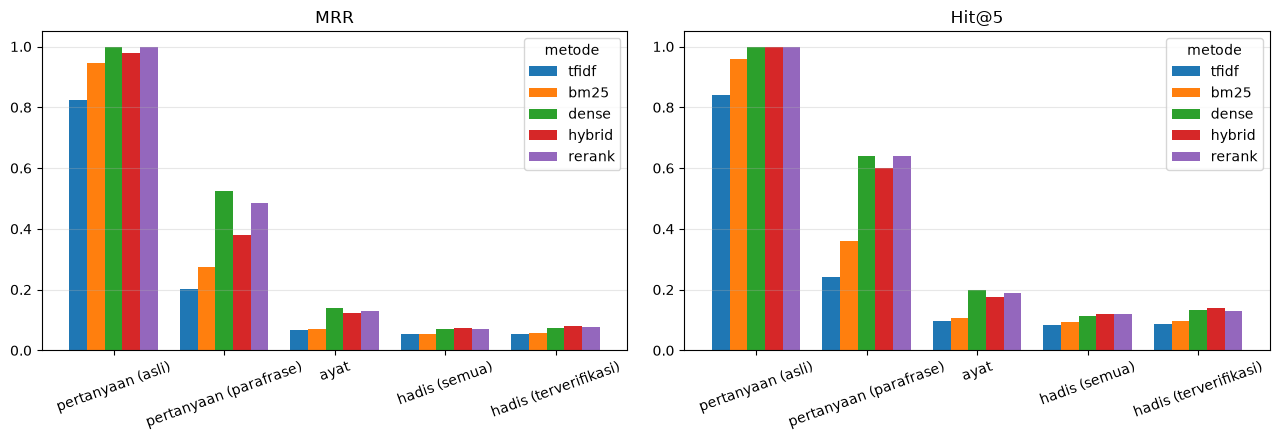

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric in zip(axes, ["MRR", "Hit@5"]):
    summary[metric].unstack("metode")[METHODS].loc[list(TASKS)].plot.bar(ax=ax, rot=20, width=0.8)
    ax.set_title(metric)
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("")
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(OUT / "eval_retrieval_metode.png", dpi=150)
plt.show()

## 5. Contoh perbedaan: soal parafrase

Soal parafrase menunjukkan kelemahan metode leksikal: kata pengguna berbeda dengan kata di judul islamqa.
Tabel berikut menampilkan peringkat dokumen kunci (`-` = tidak masuk top-10) untuk setiap metode.

In [10]:
corpus, queries, relevant_sets = TASKS["pertanyaan (parafrase)"]
compare = []
for query, relevant in zip(queries, relevant_sets):
    key = next(iter(relevant))
    row = {"query": query, "judul dokumen kunci": corpora["islamqa"].loc[key, "judul"]}
    for method in METHODS:
        ids, _ = ranked(method, corpus, query)
        row[method] = ids.index(key) + 1 if key in ids else "-"
    compare.append(row)
compare = pd.DataFrame(compare)
with pd.option_context("display.max_colwidth", 70):
    display(compare)

,query,judul dokumen kunci,tfidf,bm25,dense,hybrid,rerank
0,am i allowed to count my dhikir with a counter ring worn on my fin...,Ruling on using a tasbeeh ring,-,-,6,-,-
1,what does envy mean in islam?,Meaning of Hasad,3,1,2,1,1
2,"I secretly took caash from my parents in the past, how can i make ...",He used to take money without his parents’ knowledge; what should ...,-,-,4,2,4
3,does a housewife get rewarded for doing household chores even with...,Will a woman be rewarded for her work in the home even if she does...,-,-,1,7,1
4,"if someone left islam after a tragedy that struck him, can he stil...",A calamity befell him and he apostatized from Islam; can he repent?,-,-,-,-,-
5,can muslims use a string of beads to count their remembrance of Al...,Are Prayer Beads Allowed in Islam?,1,2,2,2,7
6,is it okay to say the remembrances more times than the number ment...,Reciting Adhkar More Than the Reported Numbers,9,1,1,1,1
7,should i lift my hands while saying the morning and evening suppli...,Is it prescribed to raise the hands when reciting the adhkaar of m...,1,1,1,1,1
8,is it wrong to say that time betrays people?,Ruling on some people saying “Time is treacherous”,-,-,1,1,1
9,what rewards does islam promise to people who stay patience during...,What Are the Virtues of Patience in Islam?,1,3,9,3,3


## 6. Kesimpulan

**MRR per tugas**

| Tugas | TF-IDF | BM25 | Dense | Hybrid | Rerank |
|---|---|---|---|---|---|
| pertanyaan (asli) | 0,824 | 0,947 | **1,000** | 0,980 | **1,000** |
| pertanyaan (parafrase) | 0,203 | 0,273 | **0,525** | 0,381 | 0,486 |
| ayat | 0,066 | 0,070 | **0,141** | 0,122 | 0,131 |
| hadis (semua) | 0,055 | 0,055 | 0,069 | **0,073** | 0,070 |
| hadis (terverifikasi) | 0,055 | 0,056 | 0,075 | **0,079** | 0,078 |

1. **Dense adalah metode terbaik secara keseluruhan.** Pada soal parafrase, MRR naik hampir 2× dibanding BM25
   (0,525 vs 0,273) dan Hit@10 dari 0,36 ke 0,76. Embedding menangkap kesamaan makna walaupun katanya berbeda
   (misalnya "name my baby … angel" → *Can You Name Your Child after an Angel?*). Untuk ayat, MRR juga naik 2× (0,141 vs 0,070).
2. **Leksikal: BM25 > TF-IDF.** Normalisasi panjang dokumen BM25 mencegah dokumen sangat pendek naik ke atas,
   kelemahan yang terlihat pada TF-IDF + cosine.
3. **Hybrid (RRF) tidak selalu lebih baik dari Dense.** Pada pertanyaan parafrase dan ayat, Hybrid di bawah Dense,
   karena BM25 yang lemah ikut berbobot sama besar: dokumen yang muncul di tengah kedua daftar bisa
   mengalahkan dokumen peringkat 1 Dense. Hybrid sedikit unggul hanya pada hadis.
4. **Rerank memperbaiki Hybrid** (parafrase 0,381 → 0,486, ayat 0,122 → 0,131), tetapi belum melampaui Dense.
   Kandidatnya berasal dari Hybrid, dan model `ms-marco-MiniLM` dilatih pada pencarian web umum, bukan teks keislaman.
   Biayanya juga paling besar: ±1,5–3,5 detik per query di CPU.
5. **Ayat & hadis tetap sulit untuk semua metode** (MRR < 0,15). Ground truth hanya berisi dalil yang dikutip islamqa,
   sehingga angka ini adalah batas bawah; dalil relevan yang tidak dikutip dihitung salah.
6. **Catatan statistik.** Soal parafrase hanya 25, jadi selisih 1 soal = 0,04 pada Hit@K. Perbedaan Dense vs Rerank
   pada tugas ini belum tentu signifikan; perbedaan pada ayat & hadis (1.000 query) lebih dapat diandalkan.

**Kecepatan (per query, CPU laptop):** TF-IDF ±2–14 ms, BM25 ±20–510 ms, Dense ±70–560 ms, Hybrid ±0,1–1 detik,
Rerank ±1,5–3,6 detik.

**Ide lanjutan:** Rerank di atas kandidat Dense (bukan Hybrid), RRF berbobot (bobot Dense lebih besar),
atau cross-encoder multibahasa/domain yang lebih sesuai.